<a href="https://colab.research.google.com/github/T1shant/EquiHealth-NLP/blob/main/CS4982.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
#Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [9]:
#Loading dataset

df = pd.read_csv("collegiate_athlete_injury_dataset.csv")
df.head()

,Athlete_ID,Sport_Type,Session_Date,Heart_Rate_BPM,Respiratory_Rate_BPM,Skin_Temperature_C,Blood_Oxygen_Level_Percent,Impact_Force_Newtons,Cumulative_Fatigue_Index,Activity_Type,Duration_Minutes,Injury_Risk_Score,Injury_Occurred
0,A0001,Basketball,2024-01-01,151,20,37.435984,95.499334,135.269735,0.481415,Jumping,22,0.627644,1
1,A0002,Tennis,2024-01-02,114,20,36.859562,98.440222,147.727352,0.757133,Running,81,0.716294,1
2,A0003,Football,2024-01-03,171,19,37.399096,96.209444,81.617217,0.584652,Jogging,66,0.658943,0
3,A0004,Soccer,2024-01-04,160,21,36.862745,99.555344,133.468431,0.386992,Dribbling,80,0.593631,1
4,A0005,Soccer,2024-01-05,120,22,36.719032,99.191327,178.474010,0.515191,Jogging,51,0.636069,1


In [10]:
#Inspecting dataset

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["Injury_Occurred"].value_counts())
print(df["Injury_Occurred"].value_counts(normalize=True))

Shape: (1000, 13)

Columns:
['Athlete_ID', 'Sport_Type', 'Session_Date', 'Heart_Rate_BPM', 'Respiratory_Rate_BPM', 'Skin_Temperature_C', 'Blood_Oxygen_Level_Percent', 'Impact_Force_Newtons', 'Cumulative_Fatigue_Index', 'Activity_Type', 'Duration_Minutes', 'Injury_Risk_Score', 'Injury_Occurred']

Missing values:
Athlete_ID                    0
Sport_Type                    0
Session_Date                  0
Heart_Rate_BPM                0
Respiratory_Rate_BPM          0
Skin_Temperature_C            0
Blood_Oxygen_Level_Percent    0
Impact_Force_Newtons          0
Cumulative_Fatigue_Index      0
Activity_Type                 0
Duration_Minutes              0
Injury_Risk_Score             0
Injury_Occurred               0
dtype: int64

Class distribution:
Injury_Occurred
1    617
0    383
Name: count, dtype: int64
Injury_Occurred
1    0.617
0    0.383
Name: proportion, dtype: float64


In [11]:
#Dropping non-predictive columns

df_model = df.drop(columns=["Athlete_ID", "Session_Date", "Injury_Risk_Score"])
df_model.head()

,Sport_Type,Heart_Rate_BPM,Respiratory_Rate_BPM,Skin_Temperature_C,Blood_Oxygen_Level_Percent,Impact_Force_Newtons,Cumulative_Fatigue_Index,Activity_Type,Duration_Minutes,Injury_Occurred
0,Basketball,151,20,37.435984,95.499334,135.269735,0.481415,Jumping,22,1
1,Tennis,114,20,36.859562,98.440222,147.727352,0.757133,Running,81,1
2,Football,171,19,37.399096,96.209444,81.617217,0.584652,Jogging,66,0
3,Soccer,160,21,36.862745,99.555344,133.468431,0.386992,Dribbling,80,1
4,Soccer,120,22,36.719032,99.191327,178.474010,0.515191,Jogging,51,1


In [12]:
#Encoding cetegorical columns into the project

df_encoded = pd.get_dummies(df_model, drop_first=True)
df_encoded.head()

,Heart_Rate_BPM,Respiratory_Rate_BPM,Skin_Temperature_C,Blood_Oxygen_Level_Percent,Impact_Force_Newtons,Cumulative_Fatigue_Index,Duration_Minutes,Injury_Occurred,Sport_Type_Basketball,Sport_Type_Football,Sport_Type_Soccer,Sport_Type_Tennis,Activity_Type_Jogging,Activity_Type_Jumping,Activity_Type_Running,Activity_Type_Sprinting
0,151,20,37.435984,95.499334,135.269735,0.481415,22,1,True,False,False,False,False,True,False,False
1,114,20,36.859562,98.440222,147.727352,0.757133,81,1,False,False,False,True,False,False,True,False
2,171,19,37.399096,96.209444,81.617217,0.584652,66,0,False,True,False,False,True,False,False,False
3,160,21,36.862745,99.555344,133.468431,0.386992,80,1,False,False,True,False,False,False,False,False
4,120,22,36.719032,99.191327,178.474010,0.515191,51,1,False,False,True,False,True,False,False,False


In [13]:
#Separating features and target

X = df_encoded.drop(columns=["Injury_Occurred"])
y = df_encoded["Injury_Occurred"]

In [14]:
#Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (800, 15)
Test set shape: (200, 15)


In [15]:
#Scaling data for Logistic Regression to use feature values that might be too sensitive to scale

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
#Logistic Regression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))

Logistic Regression Results
Accuracy: 0.595
Precision: 0.625
Recall: 0.8537
F1 Score: 0.7216
ROC-AUC: 0.5654


In [17]:
#Random forest

rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

Random Forest Results
Accuracy: 0.585
Precision: 0.6176
Recall: 0.8537
F1 Score: 0.7167
ROC-AUC: 0.5572


In [18]:
#Gradient Boosting

b = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
y_prob_gb = gb.predict_proba(X_test)[:, 1]

print("Gradient Boosting Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 4))
print("Precision:", round(precision_score(y_test, y_pred_gb), 4))
print("Recall:", round(recall_score(y_test, y_pred_gb), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_gb), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_gb), 4))

Gradient Boosting Results
Accuracy: 0.58
Precision: 0.6309
Recall: 0.7642
F1 Score: 0.6912
ROC-AUC: 0.5138


In [19]:
#Cross-validation

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_lr = cross_val_score(log_reg, X_train_scaled, y_train, cv=cv, scoring="roc_auc")
cv_rf = cross_val_score(rf, X_train, y_train, cv=cv, scoring="roc_auc")
cv_gb = cross_val_score(gb, X_train, y_train, cv=cv, scoring="roc_auc")

print("Logistic Regression CV ROC-AUC:", round(cv_lr.mean(), 4), "+/-", round(cv_lr.std(), 4))
print("Random Forest CV ROC-AUC:", round(cv_rf.mean(), 4), "+/-", round(cv_rf.std(), 4))
print("Gradient Boosting CV ROC-AUC:", round(cv_gb.mean(), 4), "+/-", round(cv_gb.std(), 4))

Logistic Regression CV ROC-AUC: 0.5883 +/- 0.0416
Random Forest CV ROC-AUC: 0.5544 +/- 0.0415
Gradient Boosting CV ROC-AUC: 0.5397 +/- 0.0224


In [20]:
best_model = rf
X_test_best = X_test
model_name = "Random Forest"
y_pred_best = y_pred_rf
y_prob_best = y_prob_rf

In [21]:
best_model = log_reg
X_test_best = X_test_scaled
model_name = "Logistic Regression"
y_pred_best = y_pred_lr
y_prob_best = y_prob_lr

In [22]:
best_model = gb
X_test_best = X_test
model_name = "Gradient Boosting"
y_pred_best = y_pred_gb
y_prob_best = y_prob_gb

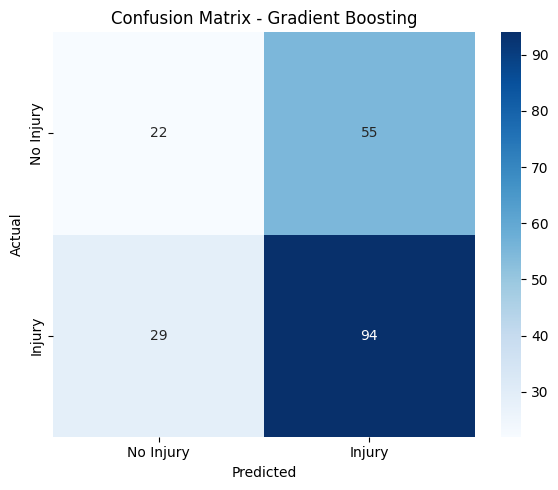

In [23]:
#Confusion matrix

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Injury", "Injury"],
    yticklabels=["No Injury", "Injury"]
)
plt.title(f"Confusion Matrix - {model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

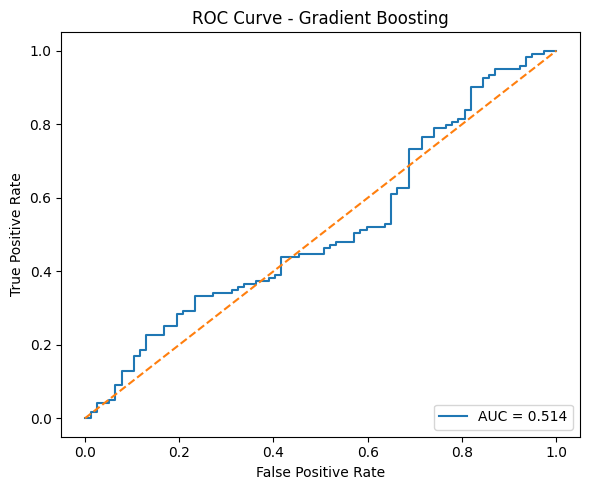

In [24]:
#ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob_best)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve - {model_name}")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

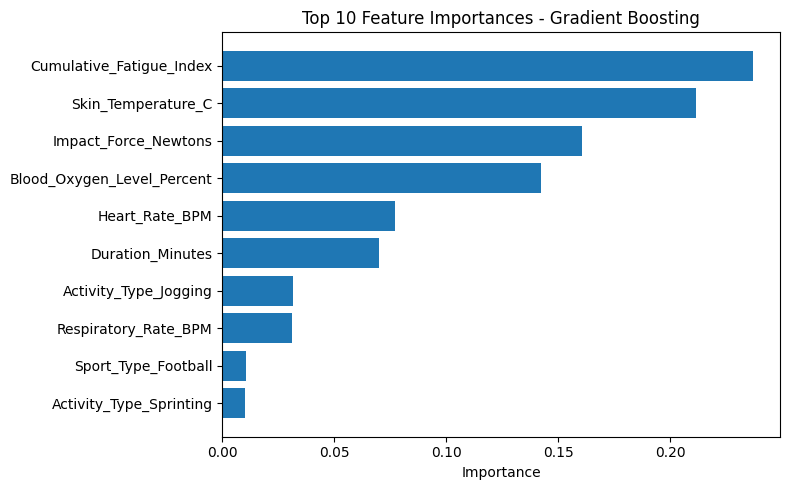

,Feature,Importance
5,Cumulative_Fatigue_Index,0.237092
2,Skin_Temperature_C,0.211589
4,Impact_Force_Newtons,0.160598
3,Blood_Oxygen_Level_Percent,0.142156
0,Heart_Rate_BPM,0.077050
6,Duration_Minutes,0.069838
11,Activity_Type_Jogging,0.031326
1,Respiratory_Rate_BPM,0.031085
8,Sport_Type_Football,0.010664
14,Activity_Type_Sprinting,0.009966


In [25]:
#Feature importance for tree-based models

importances = best_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
}).sort_values("Importance", ascending=False)

top_n = 10
top_features = importance_df.head(top_n)

plt.figure(figsize=(8,5))
plt.barh(top_features["Feature"][::-1], top_features["Importance"][::-1])
plt.xlabel("Importance")
plt.title(f"Top {top_n} Feature Importances - {model_name}")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

importance_df.head(10)

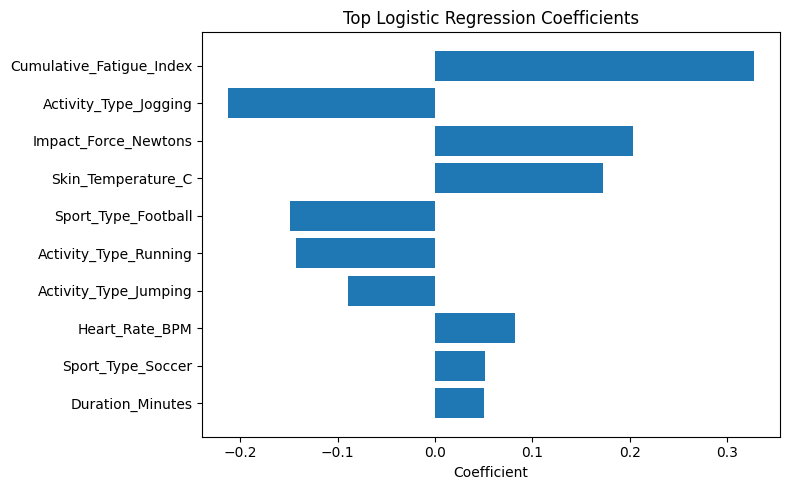

,Feature,Coefficient,AbsCoefficient
5,Cumulative_Fatigue_Index,0.327234,0.327234
11,Activity_Type_Jogging,-0.212199,0.212199
4,Impact_Force_Newtons,0.203358,0.203358
2,Skin_Temperature_C,0.172556,0.172556
8,Sport_Type_Football,-0.148454,0.148454
13,Activity_Type_Running,-0.142247,0.142247
12,Activity_Type_Jumping,-0.089711,0.089711
0,Heart_Rate_BPM,0.082374,0.082374
9,Sport_Type_Soccer,0.050934,0.050934
6,Duration_Minutes,0.050179,0.050179


In [26]:
#Logistic Regression coefficients

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_reg.coef_[0]
})

coef_df["AbsCoefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("AbsCoefficient", ascending=False)

top_n = 10
top_coef = coef_df.head(top_n)

plt.figure(figsize=(8,5))
plt.barh(top_coef["Feature"][::-1], top_coef["Coefficient"][::-1])
plt.xlabel("Coefficient")
plt.title("Top Logistic Regression Coefficients")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

coef_df.head(10)

In [27]:
#Results table

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(y_test, y_pred_lr),
        "Recall": recall_score(y_test, y_pred_lr),
        "F1 Score": f1_score(y_test, y_pred_lr),
        "ROC-AUC": roc_auc_score(y_test, y_prob_lr)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(y_test, y_pred_rf),
        "Recall": recall_score(y_test, y_pred_rf),
        "F1 Score": f1_score(y_test, y_pred_rf),
        "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
    },
    {
        "Model": "Gradient Boosting",
        "Accuracy": accuracy_score(y_test, y_pred_gb),
        "Precision": precision_score(y_test, y_pred_gb),
        "Recall": recall_score(y_test, y_pred_gb),
        "F1 Score": f1_score(y_test, y_pred_gb),
        "ROC-AUC": roc_auc_score(y_test, y_prob_gb)
    }
])

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.595,0.625000,0.853659,0.721649,0.565410
1,Random Forest,0.585,0.617647,0.853659,0.716724,0.557175
2,Gradient Boosting,0.580,0.630872,0.764228,0.691176,0.513779


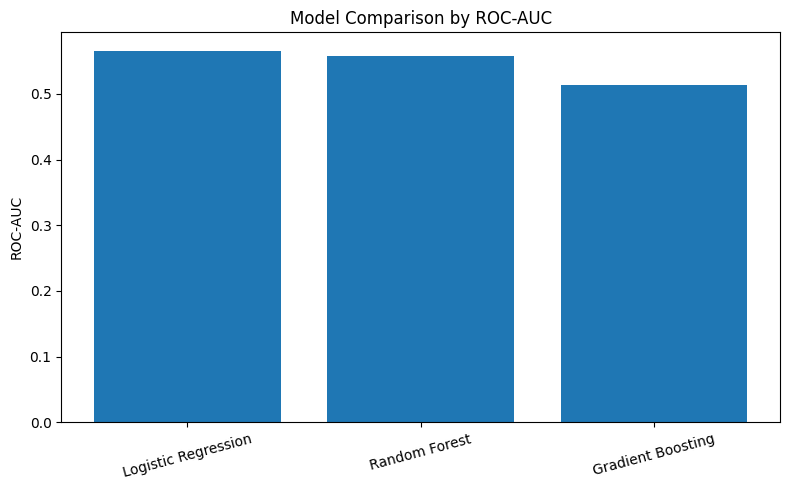

In [28]:
#Model comparison chart

plt.figure(figsize=(8,5))
plt.bar(results["Model"], results["ROC-AUC"])
plt.ylabel("ROC-AUC")
plt.title("Model Comparison by ROC-AUC")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("model_comparison_auc.png", dpi=300, bbox_inches="tight")
plt.show()

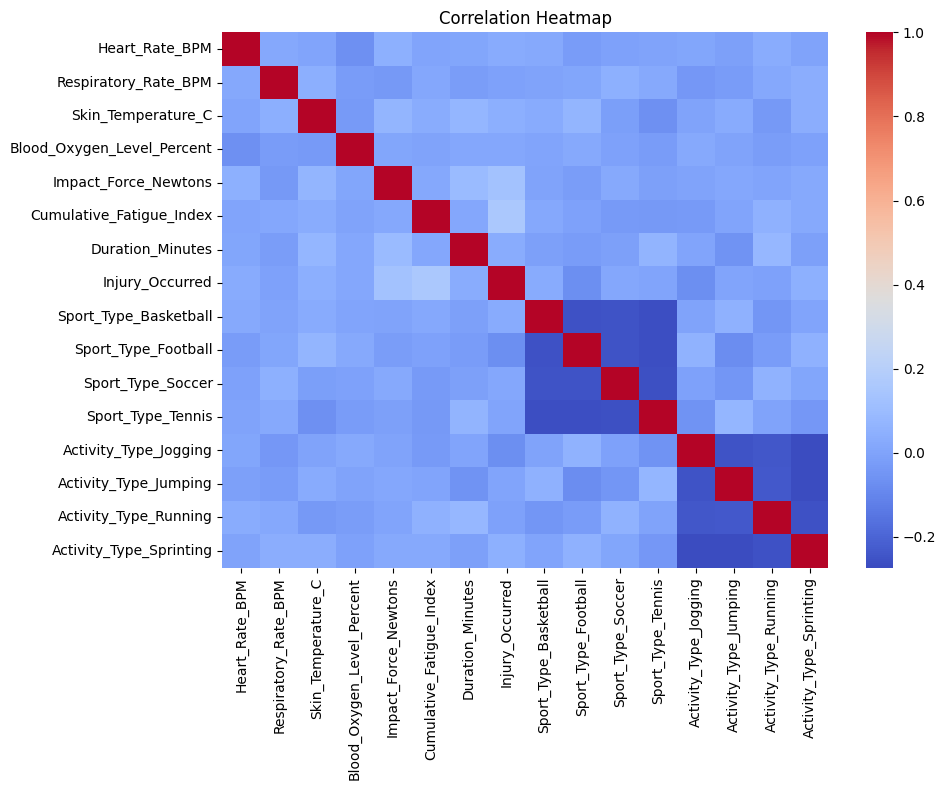

In [29]:
#Correlation heatmap

plt.figure(figsize=(10,8))
sns.heatmap(df_encoded.corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [30]:
from google.colab import files

files.download("confusion_matrix.png")
files.download("roc_curve.png")
files.download("feature_importance.png")
files.download("model_comparison_auc.png")
files.download("correlation_heatmap.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>